# Beyond Keywords
Investigating Business–Technology Confusion in News Topic Classification

Compare TF-IDF + Logistic Regression with frozen Sentence-BERT + Logistic Regression on **original English headlines only**: Business versus Science & Technology.

## Purpose and target users
This system helps readers and news content organizers sort English headlines into Business or Science & Technology. Headlines that combine financial and technical vocabulary can be difficult to categorize. We investigate how two classification methods handle these headlines.

## Experimental question
Does frozen Sentence-BERT with Logistic Regression outperform TF-IDF with Logistic Regression on headlines containing both Business and Science & Technology vocabulary?

We compare accuracy and macro F1 on the same held-out test headlines, reporting results for the full test set, the vocabulary-overlap subset, and the non-overlap subset.

## Five input files
Keep this notebook, `train.csv.gz`, `test.csv`, `business_lexicon.csv`, and `science_tech_lexicon.csv` in one folder. Open Jupyter in that folder and choose **Run All**. All project Python code and documentation are in this notebook; no `src`, `tests`, or supporting documents are required.

`train.csv.gz` contains the original training CSV compressed to save space. Python reads it directly; do not extract it. Both datasets retain the original three fields: class index, title, description. Only classes 3 and 4 and only titles enter the experiment. Development is split from training after duplicate control.

The notebook creates one `outputs/` folder for processed data, fitted models, caches, audits and current results. These are generated files, not extra inputs. `REBUILD=True` rebuilds the experiment; after a successful run, `False` reuses local outputs. Internet is needed for the pinned SBERT encoder on first use, not to download the supplied news data.

## Setup
Recommended: Python 3.12 in a separate environment. Install once in Anaconda Prompt or a terminal (not a notebook diagnostic cell):

```bash
python -m pip install "numpy>=2.1,<3" "pandas>=2.2,<3" "scipy>=1.14,<2" "scikit-learn>=1.6,<2" "joblib>=1.4,<2" "torch>=2.6,<3" "sentence-transformers>=6.3,<7" "transformers>=5,<6" "huggingface-hub>=1.3,<3" "matplotlib>=3.10,<4" jupyterlab socksio
python -m jupyter lab
```

Package versions are recorded in the Setup section. Saved outputs show the results of the completed run. To reproduce the experiment, restart the kernel and run all cells in order.

In [1]:
#Beyond Keywords: transparent headline classification and evaluation pipeline.
from pathlib import Path
import csv, gzip, hashlib, html, json, re, time, unicodedata, urllib.request, warnings
from collections import defaultdict
import numpy as np
import pandas as pd
import joblib
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.exceptions import ConvergenceWarning

ROOT = Path.cwd()
LABELS = ['Business', 'Science & Technology']
SEED = 42
MODEL = 'sentence-transformers/all-MiniLM-L6-v2'
REVISION = '1110a243fdf4706b3f48f1d95db1a4f5529b4d41'
EXPECTED = {'train.csv':'76a0a2d2f92b286371fe4d4044640910a04a803fdd2538e0f3f29a5c6f6b672e', 'test.csv':'521465c2428ed7f02f8d6db6ffdd4b5447c1c701962353eb2c40d548c3c85699'}

from IPython.display import display
REBUILD = True

In [2]:
import sys
from importlib.metadata import version, PackageNotFoundError

print("Environment: Jupyter Notebook")
print("Python:", sys.version.split()[0])
print("\nPackage versions:")

packages = ["numpy","pandas","scipy","scikit-learn","joblib","torch","sentence-transformers",
    "transformers","huggingface-hub","matplotlib","ipython","socksio",]

for package in packages:
    try:
        print(f"{package}: {version(package)}")
    except PackageNotFoundError:
        print(f"{package}: NOT INSTALLED")

Environment: Jupyter Notebook
Python: 3.13.5

Package versions:
numpy: 2.1.3
pandas: 2.2.3
scipy: 1.15.3
scikit-learn: 1.6.1
joblib: 1.4.2
torch: 2.14.0
sentence-transformers: 6.3.0
transformers: 5.18.0
huggingface-hub: 1.33.0
matplotlib: 3.10.0
ipython: 8.30.0
socksio: 1.0.0


In [3]:
def save_json(path, obj):
    p = ROOT / path; p.parent.mkdir(parents=True, exist_ok=True)
    p.write_text(json.dumps(obj, indent=2, ensure_ascii=False, default=str)+'\n')

def load_json(path): return json.loads((ROOT/path).read_text())

def digest(value): return hashlib.sha256(value.encode()).hexdigest()

def normalize(text):
    text = html.unescape(unicodedata.normalize('NFKC', str(text))).casefold()
    return ' '.join(re.findall(r'[a-z0-9]+', text))

def validate_inputs():
    """Read bundled data locally; no dataset download or archive extraction."""
    for name, expected in EXPECTED.items():
        path = ROOT / name
        if name == 'train.csv':
            path = ROOT / 'train.csv.gz'
        if not path.is_file():
            raise FileNotFoundError(f'Keep all five project files together. Missing: {path.name}')
        h = hashlib.sha256()
        opener = gzip.open if path.suffix == '.gz' else open
        with opener(path, 'rb') as stream:
            for chunk in iter(lambda: stream.read(1024 * 1024), b''):
                h.update(chunk)
        if h.hexdigest() != expected:
            raise ValueError(f'Dataset checksum mismatch: {path.name}')
    return ['World', 'Sports', 'Business', 'Sci/Tech']

## Data audit and splits
Official test identities are held out. Exact and conservative near-duplicate groups are connected; linked training records and conflicting-label groups are removed. One consistent representative remains per group. Near-duplicate rule: at least six unique tokens, deletion signatures, Jaccard ≥ 0.8 and character similarity ≥ 0.92. It can miss paraphrases. Training/development split: stratified 90/10, seed 42. Description is retained for provenance but never passed to either model.

In [4]:
def prepare_data():
    """Preserve official test; remove linked train rows and duplicate representatives."""
    for directory in ['outputs/results', 'outputs/artifacts', 'outputs/processed']:
        (ROOT / directory).mkdir(parents=True, exist_ok=True)
    validate_inputs(); records=[]; removed=[]; before={}
    for split in ['train','test']:
        n=0
        opener = gzip.open if split == 'train' else open
        path = ROOT / ('train.csv.gz' if split == 'train' else 'test.csv')
        with opener(path, 'rt', newline='', encoding='utf-8') as f:
            for i,row in enumerate(csv.reader(f)):
                sid=f'{split}:{i+1:06d}'
                if len(row)!=3 or row[0] not in ['1','2','3','4']:
                    removed.append({'id':sid,'reason':'malformed record'}); continue
                if row[0] not in ['3','4']: continue
                n+=1
                text=row[1]  # Original title retained. Never split a combined text field.
                if not normalize(text): removed.append({'id':sid,'reason':'empty normalized title'}); continue
                records.append({'id':sid,'official_split':split,'label':int(row[0])-3,'title':text,'description':row[2],'fingerprint':digest(normalize(text)),'normalized':normalize(text)})
        before[split]=n
    df=pd.DataFrame(records); parent=list(range(len(df)))
    def find(i):
        while parent[i]!=i: parent[i]=parent[parent[i]]; i=parent[i]
        return i
    def union(i,j):
        a,b=find(i),find(j)
        if a!=b: parent[max(a,b)]=min(a,b)
    exact={}; buckets=defaultdict(list); near=[]
    # A reproducible conservative near-duplicate rule. Identical token sets or one
    # token substitution/deletion with >= 6 unique tokens, Jaccard >= .8 and
    # character SequenceMatcher similarity >= .92. It cannot catch all paraphrases.
    from difflib import SequenceMatcher
    token_sets=[set(x.split()) for x in df.normalized]
    for i,row in df.iterrows():
        fp=row.fingerprint
        if fp in exact: union(i,exact[fp])
        else: exact[fp]=i
        ts=sorted(token_sets[i])
        if len(ts)<6: continue
        signatures={tuple(ts)} | {tuple(ts[:j]+ts[j+1:]) for j in range(len(ts))}
        candidates=set()
        for sig in signatures: candidates.update(buckets[sig])
        for j in sorted(candidates):
            a,b=token_sets[i],token_sets[j]
            jac=len(a&b)/len(a|b)
            if jac>=.8 and SequenceMatcher(None,row.normalized,df.iloc[j].normalized,autojunk=False).ratio()>=.92:
                union(i,j); near.append({'id_a':df.iloc[j].id,'id_b':row.id,'jaccard':jac})
        # Store only exact-text representatives to limit redundant comparisons.
        if exact[fp]==i:
            for sig in signatures: buckets[sig].append(i)
    df['group']=[f'g{find(i):06d}' for i in range(len(df))]
    keep=[]
    for group,g in df.groupby('group',sort=True):
        test=g[g.official_split=='test']
        if g.label.nunique()>1:
            for sid in g.id: removed.append({'id':sid,'reason':'conflicting-label duplicate group','group':group})
            continue
        chosen=(test if len(test) else g).iloc[0]
        keep.append(chosen.name)
        for _,r in g.iterrows():
            if r.name==chosen.name: continue
            why='linked to official test' if len(test) and r.official_split=='train' else 'repeated duplicate group'
            removed.append({'id':r.id,'reason':why,'group':group,'retained_id':chosen.id})
    clean=df.loc[keep].copy(); tr=clean[clean.official_split=='train']
    train,dev=train_test_split(tr,test_size=.1,random_state=SEED,stratify=tr.label)
    test=clean[clean.official_split=='test']
    splits={'train':train.sort_values('id'),'dev':dev.sort_values('id'),'test':test.sort_values('id')}
    for a,b in [('train','dev'),('train','test'),('dev','test')]:
        assert not set(splits[a].id)&set(splits[b].id)
        assert not set(splits[a].group)&set(splits[b].group)
        assert not set(splits[a].fingerprint)&set(splits[b].fingerprint)
    out=ROOT/'outputs/processed';out.mkdir(parents=True,exist_ok=True)
    for name,s in splits.items(): s.to_csv(out/f'{name}.csv',index=False)
    pd.DataFrame(removed).to_csv(ROOT/'outputs/results/removals.csv',index=False)
    pd.DataFrame(near,columns=['id_a','id_b','jaccard']).to_csv(ROOT/'outputs/results/near_duplicate_pairs.csv',index=False)
    counts={k:{'total':len(v),'classes':{LABELS[int(y)]:int(n) for y,n in v.label.value_counts().items()}} for k,v in splits.items()}
    save_json('outputs/results/data_audit.json',{'before_selected':before,'after':counts,'removal_count':len(removed),'removal_reasons':pd.Series([r['reason'] for r in removed]).value_counts().to_dict(),'near_duplicate_links':len(near),'checks':'ID, fingerprint and connected duplicate groups disjoint across all splits','test_population':'One representative per consistent duplicate group; conflicting groups excluded; official test records never moved to training.'})
    return splits

def splits():
    return {n: pd.read_csv(ROOT/f'outputs/processed/{n}.csv', keep_default_na=False)
            for n in ['train', 'dev', 'test']}

In [5]:
if REBUILD:
    data = prepare_data()
else:
    validate_inputs()
    data = splits()
for a, b in [('train','dev'), ('train','test'), ('dev','test')]:
    for field in ['id','group','fingerprint']:
        assert not set(data[a][field]) & set(data[b][field])
display(pd.DataFrame({name: d.label.value_counts() for name,d in data.items()}).rename(index=dict(enumerate(LABELS))))
print(json.dumps(load_json('outputs/results/data_audit.json'), indent=2))

,train,dev,test
label,,,
Business,24598,2734,1839
Science & Technology,23518,2613,1842


{
  "before_selected": {
    "train": 60000,
    "test": 3800
  },
  "after": {
    "train": {
      "total": 48116,
      "classes": {
        "Business": 24598,
        "Science & Technology": 23518
      }
    },
    "dev": {
      "total": 5347,
      "classes": {
        "Business": 2734,
        "Science & Technology": 2613
      }
    },
    "test": {
      "total": 3681,
      "classes": {
        "Science & Technology": 1842,
        "Business": 1839
      }
    }
  },
  "removal_count": 6656,
  "removal_reasons": {
    "repeated duplicate group": 4486,
    "conflicting-label duplicate group": 1475,
    "linked to official test": 695
  },
  "near_duplicate_links": 5065,
  "checks": "ID, fingerprint and connected duplicate groups disjoint across all splits",
  "test_population": "One representative per consistent duplicate group; conflicting groups excluded; official test records never moved to training."
}


## Two separate lexicons
The supplied CSVs are the frozen v1.0 term lists derived from training candidate statistics and AI-assisted semantic review of training candidates and a seeded development sample, without model predictions. Loading them replays documented choices; it does not constitute new student review. Science & Technology includes computing, technology and natural science.

Whole-token/phrase matching uses NFKC normalization, HTML unescaping, lowercase and alphanumeric tokens. A headline is **overlap** if it matches at least one term from each list. This is an analysis rule, not an input dictionary used to train the classifiers. Polysemy (e.g. shares, rates, virus) creates false positives. Do not revise these lists based on observed test results.

In [6]:
def load_lexicons():
    result = {}
    for label, filename in zip(LABELS, ['business_lexicon.csv','science_tech_lexicon.csv']):
        table = pd.read_csv(ROOT/filename, keep_default_na=False)
        if 'term' not in table or table.empty:
            raise ValueError(f'{filename} must contain a non-empty term column.')
        terms = [normalize(t) for t in table.term]
        if any(not t for t in terms) or len(set(terms)) != len(terms):
            raise ValueError(f'{filename} contains blank or duplicate terms.')
        result[label] = sorted(terms)
    return result

In [7]:
def lexicon_candidates():
    tr=splits()['train']
    cv=CountVectorizer(ngram_range=(1,2),min_df=15,stop_words='english',binary=True,token_pattern=r'(?u)\b[a-zA-Z][a-zA-Z]+\b')
    x=cv.fit_transform(tr.title); terms=cv.get_feature_names_out(); counts=np.vstack([np.asarray(x[tr.label.to_numpy()==y].sum(axis=0)).ravel() for y in [0,1]])
    ns=np.array([(tr.label==y).sum() for y in [0,1]])
    odds=np.log((counts+.5)/(ns[:,None]-counts+.5)); rows=[]
    for y in [0,1]:
        score=odds[y]-odds[1-y]; idx=np.argsort(-score)
        chosen=list(idx[:120]); chosen += [j for j in np.argsort(-counts[y]) if score[j]>.35 and j not in chosen][:80]
        for j in chosen: rows.append({'label':LABELS[y],'term':terms[j],'document_frequency':int(counts[y,j]),'other_frequency':int(counts[1-y,j]),'log_odds_difference':float(score[j])})
    pd.DataFrame(rows).to_csv(ROOT/'outputs/results/lexicon_candidates.csv',index=False)
    return pd.DataFrame(rows)

def match_terms(text,lexicon):
    s=' '+normalize(text)+' '
    return {label:[t for t in terms if ' '+normalize(t)+' ' in s] for label,terms in lexicon.items()}

def annotate(df,lexicon):
    d=df.copy(); m=[match_terms(t,lexicon) for t in d.title]
    d['business_terms']=[json.dumps(x[LABELS[0]]) for x in m]
    d['science_terms']=[json.dumps(x[LABELS[1]]) for x in m]
    d['overlap']=[bool(x[LABELS[0]] and x[LABELS[1]]) for x in m]
    return d

In [8]:
def build_review():
    c=pd.read_csv(ROOT/'outputs/results/lexicon_candidates.csv'); requested=load_lexicons();lex={}
    review=[]
    for label,terms in requested.items():
        available=set(c[c.label==label].term)
        missing=set(terms)-available
        assert not missing, missing
        lex[label]=sorted(terms)
    for _,r in c.iterrows():
        selected=r.term in lex[r.label]
        reason='Retained: financial/economic topic term' if r.label==LABELS[0] else 'Retained: technology/computing/natural-science topic term'
        if not selected:reason='Excluded: generic context, publisher/source, company/person entity, ambiguous fragment or overly specific/duplicate phrase'
        review.append({**r.to_dict(),'decision':'retain' if selected else 'exclude','reason':reason})
    pd.DataFrame(review).to_csv(ROOT/'outputs/results/lexicon_term_review.csv',index=False)
    save_json('outputs/artifacts/lexicons.json',lex)
    dev=annotate(splits()['dev'],lex);sample=dev[dev.overlap].sample(n=min(20,int(dev.overlap.sum())),random_state=SEED).sort_values('id')
    sample[['id','title','business_terms','science_terms']].to_csv(ROOT/'outputs/results/development_overlap_review.csv',index=False)
    save_json('outputs/artifacts/lexicon_review.json',{'version':'1.0','source_split':'train only','source_manifest_sha256':hashlib.sha256((ROOT/'outputs/processed/train.csv').read_bytes()).hexdigest(),'normalization':'NFKC, HTML unescape, casefold, alphanumeric tokens, whitespace collapse','ranking':'class document-presence log odds with 0.5 smoothing; top 120 log-odds plus 80 highest-frequency remaining terms with positive log odds >0.35; min_df=15','stopwords':'sklearn English candidate extraction only; classifiers keep stopwords','decision_author':'AI-assisted researcher review; students must review before claiming authorship','dev_overlap_n':int(dev.overlap.sum()),'dev_class_counts':dev[dev.overlap].label.value_counts().to_dict(),'dev_sample':'outputs/results/development_overlap_review.csv','dev_review_status':'sample prepared for semantic review before freeze','test_consulted':False,'predictions_used':False,'limitations':['proxy for mixed vocabulary, not semantic ambiguity','entity names excluded so technology companies alone do not count','polysemy: virus, security, bank and shares can have multiple senses','class frequency selection and 2004-era dataset limit coverage','natural science terms included when supported by training']})
    print(sample[['id','title','business_terms','science_terms']].to_string(index=False))
    print('Overlap development',int(dev.overlap.sum()),'of',len(dev))


def finish_review():
    p=ROOT/'outputs/results/development_overlap_review.csv';d=pd.read_csv(p)
    comments={
      'train:019091':('polysemy false positive','Rates refers to divorce frequency, not financial interest rates. Retain rates for finance and disclose this lexical false positive.'),
      'train:078941':('polysemy false positive','Shares means tells others about dreams, not financial shares. Retain shares globally because it is a central financial term; disclose proxy noise.'),
      'train:087762':('metaphorical business wording','Bank on is figurative. Business topic remains plausible because sneaker makers are firms; proxy alone cannot settle semantic ambiguity.'),
      'train:009813':('entity ambiguity','China Mobile is a company name. Mobile matches lexical technology vocabulary without proving a product-focused story.')
    }
    d['review_judgement']=[comments.get(x,('plausible mixed vocabulary','Business transaction/price/performance language co-occurs with a technology or science term.'))[0] for x in d.id]
    d['review_note']=[comments.get(x,('plausible mixed vocabulary','Business transaction/price/performance language co-occurs with a technology or science term.'))[1] for x in d.id]
    d.to_csv(p,index=False)
    r=load_json('outputs/artifacts/lexicon_review.json');r['dev_review_status']='Reviewed 20 seeded development headlines semantically, without predictions; retained central financial terms despite documented polysemy.';r['revision_decisions']=['Initial seeded sample included train:011065 NASA Experts Report Drought Forecast Breakthrough. Removed forecast because it is generic. Re-reviewed seeded sample after this single change; no test or predictions consulted.'];r['decision_rule']='Use frozen v1.0 lexical proxy with explicit polysemy limitations; do not redesign using test.'
    save_json('outputs/artifacts/lexicon_review.json',r)

In [9]:
if REBUILD:
    lexicon_candidates()
    build_review()
    finish_review()
lexicons = load_json('outputs/artifacts/lexicons.json')
assert lexicons == load_lexicons(), 'Lexicon inputs changed: rebuild before evaluation.'
print({label: len(terms) for label, terms in lexicons.items()})
display(pd.read_csv(ROOT/'outputs/results/development_overlap_review.csv').head(10))

          id                                                                title business_terms         science_terms
train:001642                           Real Slashes Online Song Prices (PC World)     ["prices"]      ["online", "pc"]
train:005913                                Online retail sales continue to surge      ["sales"]            ["online"]
train:009244 Japan #39;s NTT DoCoMo, Motorola strike deal to develop mobile phone       ["deal"]   ["mobile", "phone"]
train:009705                              Amazon to sell AT T's Net phone service       ["sell"]             ["phone"]
train:009813        Asian Stocks: Japan Climbs, Led by UFJ; China Mobile Advances     ["stocks"]            ["mobile"]
train:015178                                      Charter Sets Phone Service Deal       ["deal"]             ["phone"]
train:017523                                        Cell phone sales keep booming      ["sales"]             ["phone"]
train:019091                 Old-Flame Web Sites

,id,title,business_terms,science_terms,review_judgement,review_note
0,train:001642,Real Slashes Online Song Prices (PC World),"[""prices""]","[""online"", ""pc""]",plausible mixed vocabulary,Business transaction/price/performance languag...
1,train:005913,Online retail sales continue to surge,"[""sales""]","[""online""]",plausible mixed vocabulary,Business transaction/price/performance languag...
2,train:009244,"Japan #39;s NTT DoCoMo, Motorola strike deal t...","[""deal""]","[""mobile"", ""phone""]",plausible mixed vocabulary,Business transaction/price/performance languag...
3,train:009705,Amazon to sell AT T's Net phone service,"[""sell""]","[""phone""]",plausible mixed vocabulary,Business transaction/price/performance languag...
4,train:009813,"Asian Stocks: Japan Climbs, Led by UFJ; China ...","[""stocks""]","[""mobile""]",entity ambiguity,China Mobile is a company name. Mobile matches...
5,train:015178,Charter Sets Phone Service Deal,"[""deal""]","[""phone""]",plausible mixed vocabulary,Business transaction/price/performance languag...
6,train:017523,Cell phone sales keep booming,"[""sales""]","[""phone""]",plausible mixed vocabulary,Business transaction/price/performance languag...
7,train:019091,Old-Flame Web Sites Boosting Divorce Rates (Re...,"[""rates""]","[""web""]",polysemy false positive,"Rates refers to divorce frequency, not financi..."
8,train:033584,"Tech groups push for R D credit, Internet tax ban","[""tax""]","[""internet"", ""tech""]",plausible mixed vocabulary,Business transaction/price/performance languag...
9,train:044249,Chip-Maker Posts Profitable Quarter,"[""quarter""]","[""chip""]",plausible mixed vocabulary,Business transaction/price/performance languag...


## Method 1 — TF-IDF + Logistic Regression
Fit vocabulary/IDF and classifier on training only. Select development Macro F1 over C ∈ {0.5, 1, 2} and unigram/bigram settings. Ties prefer lower C then unigrams. No train+development refit. Stopwords are retained in classifier inputs. Non-convergence stops the run.

In [10]:
def score(y,p):
    return {'accuracy':float(accuracy_score(y,p)),'macro_f1':float(f1_score(y,p,labels=[0,1],average='macro',zero_division=0))}

def fit_checked(model,x,y):
    with warnings.catch_warnings(record=True) as ws:
        warnings.simplefilter('always',ConvergenceWarning); model.fit(x,y)
    conv=not any(issubclass(w.category,ConvergenceWarning) for w in ws)
    if not conv: raise RuntimeError('Classifier failed to converge; revise development protocol before final testing.')
    return model

def train_tfidf():
    d=splits();tr,dev=d['train'],d['dev']; candidates=[];best=None
    start=time.perf_counter()
    # Iteration order is tie break: lower C, then unigram. No train+dev refit.
    for c in [.5,1.,2.]:
        for n in [1,2]:
            m=Pipeline([('tfidf',TfidfVectorizer(ngram_range=(1,n),min_df=2,sublinear_tf=True,max_features=80000)),('lr',LogisticRegression(C=c,solver='liblinear',max_iter=2000,random_state=SEED))])
            fit_checked(m,tr.title,tr.label); scores=score(dev.label,m.predict(dev.title));r={'C':c,'ngram_max':n,**scores,'converged':True};candidates.append(r)
            if best is None or r['macro_f1']>best[0]['macro_f1']+1e-12:best=(r,m)
    joblib.dump(best[1],ROOT/'outputs/artifacts/tfidf.joblib')
    feature_names=best[1]['tfidf'].get_feature_names_out(); coef=best[1]['lr'].coef_[0]
    ix=np.r_[np.argsort(coef)[:15],np.argsort(coef)[-15:][::-1]]
    pd.DataFrame({'term':feature_names[ix],'weight_toward_science':coef[ix]}).to_csv(ROOT/'outputs/results/feature_weights.csv',index=False)
    save_json('outputs/results/tfidf_development.json',{'candidates':candidates,'selected':best[0],'seconds':time.perf_counter()-start,'fit_policy':'train only, selected on dev; no refit','solver':'liblinear','max_iter':2000,'classes':best[1].classes_.tolist()})
    return best[0]

In [11]:
if REBUILD:
    print(train_tfidf())
display(pd.DataFrame(load_json('outputs/results/tfidf_development.json')['candidates']))
display(pd.read_csv(ROOT/'outputs/results/feature_weights.csv'))

{'C': 2.0, 'ngram_max': 2, 'accuracy': 0.8911539180849074, 'macro_f1': 0.8911069907825884, 'converged': True}


,C,ngram_max,accuracy,macro_f1,converged
0,0.5,1,0.884608,0.884568,True
1,0.5,2,0.884234,0.884176,True
2,1.0,1,0.887601,0.887560,True
3,1.0,2,0.891154,0.891096,True
4,2.0,1,0.889845,0.889791,True
5,2.0,2,0.891154,0.891107,True


,term,weight_toward_science
0,oil,-10.862771
1,stocks,-8.308568
2,dollar,-8.229192
3,economy,-7.305549
4,profit,-6.604755
5,tax,-6.103995
6,yukos,-6.074703
7,enron,-5.644824
8,bank,-5.423667
9,sec,-5.331713


## Method 2 — Frozen Sentence-BERT + Logistic Regression
Pinned `all-MiniLM-L6-v2` produces 384-dimensional L2-normalized embeddings (maximum sequence length 256). Encoder weights stay frozen; only Logistic Regression is trained, with C chosen on development. No encoder fine-tuning. Cached embeddings are bound to ordered IDs, exact title text and encoder configuration.

In [12]:
def encoder():
    from sentence_transformers import SentenceTransformer
    import torch
    torch.set_num_threads(4)
    m=SentenceTransformer(MODEL,revision=REVISION,device='cpu')
    m.max_seq_length=256; m.eval()
    for p in m.parameters(): p.requires_grad=False
    return m

def embed(m,df,name):
    cfg={'model':MODEL,'revision':REVISION,'dimension':384,'max_seq_length':256,'normalization':'L2','pooling':'mean with attention mask','batch_size':128,'device':'cpu'}
    key=digest(json.dumps({'ids':df.id.tolist(),'fingerprints':[digest(t) for t in df.title],'config':cfg},sort_keys=True))
    cache=ROOT/f'outputs/artifacts/embeddings_{name}.npz'
    if cache.exists():
        z=np.load(cache,allow_pickle=False)
        if str(z['key'])==key:
            assert np.array_equal(z['ids'],df.id.to_numpy(dtype=str));return z['embeddings']
    e=m.encode(df.title.tolist(),batch_size=128,normalize_embeddings=True,show_progress_bar=True,convert_to_numpy=True)
    assert e.shape==(len(df),384) and np.isfinite(e).all()
    np.savez_compressed(cache,key=key,ids=df.id.to_numpy(dtype=str),embeddings=e)
    save_json('outputs/artifacts/encoder_config.json',cfg)
    return e

def train_sbert():
    d=splits(); m=encoder(); start=time.perf_counter();x=embed(m,d['train'],'train');v=embed(m,d['dev'],'dev');cand=[];best=None
    for c in [.5,1.,2.]:
        lr=fit_checked(LogisticRegression(C=c,solver='liblinear',max_iter=2000,random_state=SEED),x,d['train'].label)
        r={'C':c,**score(d['dev'].label,lr.predict(v)),'converged':True};cand.append(r)
        if best is None or r['macro_f1']>best[0]['macro_f1']+1e-12:best=r,lr
    joblib.dump(best[1],ROOT/'outputs/artifacts/sbert_lr.joblib')
    save_json('outputs/results/sbert_development.json',{'candidates':cand,'selected':best[0],'seconds':time.perf_counter()-start,'solver':'liblinear','max_iter':2000,'fit_policy':'frozen encoder, train only classifier, no refit'})
    return best[0]

In [13]:
if REBUILD:
    print(train_sbert())
display(pd.DataFrame(load_json('outputs/results/sbert_development.json')['candidates']))
print(json.dumps(load_json('outputs/artifacts/encoder_config.json'), indent=2))

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

{'C': 0.5, 'accuracy': 0.8629137834299607, 'macro_f1': 0.862832702836743, 'converged': True}


,C,accuracy,macro_f1,converged
0,0.5,0.862914,0.862833,True
1,1.0,0.861418,0.861336,True
2,2.0,0.858425,0.858344,True


{
  "model": "sentence-transformers/all-MiniLM-L6-v2",
  "revision": "1110a243fdf4706b3f48f1d95db1a4f5529b4d41",
  "dimension": 384,
  "max_seq_length": 256,
  "normalization": "L2",
  "pooling": "mean with attention mask",
  "batch_size": 128,
  "device": "cpu"
}


## Results — Freeze protocol and final evaluation
Hash-lock splits, both lexicon input files, derived lexicons, models, configuration and development choices before evaluation. Both methods use identical held-out test IDs. Report all, overlap and non-overlap populations; Macro F1 always uses both classes and zero_division=0. Test results must not select revisions.

In [14]:
def freeze():
    paths=['business_lexicon.csv','science_tech_lexicon.csv','outputs/processed/train.csv','outputs/processed/dev.csv','outputs/processed/test.csv','outputs/artifacts/lexicons.json','outputs/artifacts/lexicon_review.json','outputs/artifacts/tfidf.joblib','outputs/artifacts/sbert_lr.joblib','outputs/artifacts/encoder_config.json','outputs/results/tfidf_development.json','outputs/results/sbert_development.json']
    hashes={p:hashlib.sha256((ROOT/p).read_bytes()).hexdigest() for p in paths}
    save_json('outputs/artifacts/frozen_protocol.json',{'sha256':hashes,'seed':SEED,'input':'original title only','selection':'dev Macro F1; ties lower C then unigram','test_use':'final evaluation only','overlap_rule':'at least one normalized whole token or phrase from each frozen training-derived lexicon','labels':LABELS})
    return hashes

def evaluate():
    protocol=load_json('outputs/artifacts/frozen_protocol.json')
    for p,h in protocol['sha256'].items(): assert hashlib.sha256((ROOT/p).read_bytes()).hexdigest()==h, 'Protocol changed after freeze'
    d=splits();t=annotate(d['test'],load_json('outputs/artifacts/lexicons.json'));a=joblib.load(ROOT/'outputs/artifacts/tfidf.joblib');b=joblib.load(ROOT/'outputs/artifacts/sbert_lr.joblib');m=encoder();e=embed(m,t,'test')
    t['tfidf_prediction']=a.predict(t.title);t['sbert_prediction']=b.predict(e)
    result=[]
    for subset,mask in [('all',np.ones(len(t),dtype=bool)),('overlap',t.overlap.to_numpy()),('non_overlap',~t.overlap.to_numpy())]:
        z=t.loc[mask]
        for model in ['tfidf','sbert']:
            pred=z[f'{model}_prediction']; row={'subset':subset,'model':model,'support':len(z),'business_n':int((z.label==0).sum()),'science_n':int((z.label==1).sum())}
            row.update(score(z.label,pred) if len(z) else {'accuracy':None,'macro_f1':None}); result.append(row)
            save_json(f'outputs/results/{model}_{subset}_classification.json',{'label_order':LABELS,'confusion_matrix':confusion_matrix(z.label,pred,labels=[0,1]).tolist(),'report':classification_report(z.label,pred,labels=[0,1],target_names=LABELS,zero_division=0,output_dict=True) if len(z) else None})
    t.to_csv(ROOT/'outputs/results/test_predictions.csv',index=False);pd.DataFrame(result).to_csv(ROOT/'outputs/results/comparison.csv',index=False);save_json('outputs/results/comparison.json',result)
    err=t[(t.label!=t.tfidf_prediction)|(t.label!=t.sbert_prediction)].sort_values(['overlap','id'],ascending=[False,True]);err.head(12).to_csv(ROOT/'outputs/results/errors_for_analysis.csv',index=False)
    t[t.tfidf_prediction!=t.sbert_prediction].to_csv(ROOT/'outputs/results/disagreements.csv',index=False)
    fixed=d['dev'].head(8)
    before=a.predict(fixed.title);again=joblib.load(ROOT/'outputs/artifacts/tfidf.joblib').predict(fixed.title);assert np.array_equal(before,again)
    ve=embed(m,d['dev'],'dev')[:8];assert np.array_equal(b.predict(ve),joblib.load(ROOT/'outputs/artifacts/sbert_lr.joblib').predict(ve))
    save_json('outputs/results/reload_check.json',{'tfidf':True,'sbert_classifier':True,'examples':fixed.id.tolist()})
    return pd.DataFrame(result)

In [15]:
if REBUILD:
    freeze()
comparison = evaluate()
display(comparison.round(4))

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

,subset,model,support,business_n,science_n,accuracy,macro_f1
0,all,tfidf,3681,1839,1842,0.9027,0.9027
1,all,sbert,3681,1839,1842,0.8601,0.8601
2,overlap,tfidf,42,15,27,0.8571,0.8444
3,overlap,sbert,42,15,27,0.7143,0.6786
4,non_overlap,tfidf,3639,1824,1815,0.9033,0.9033
5,non_overlap,sbert,3639,1824,1815,0.8618,0.8618


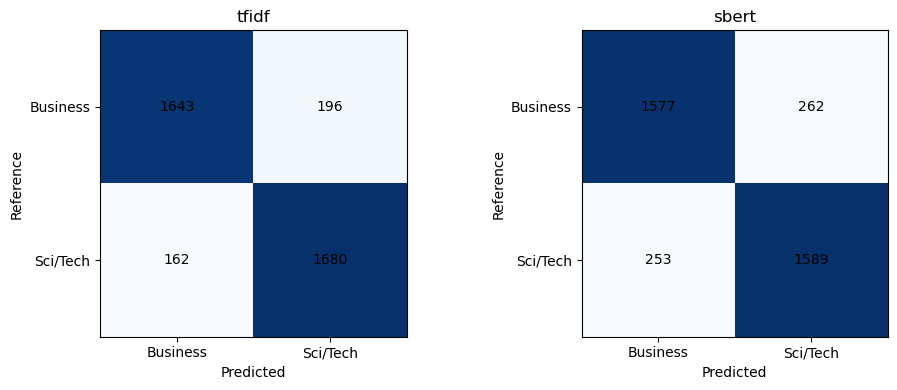

tfidf


,precision,recall,f1-score,support
Business,0.910249,0.893420,0.901756,1839.000000
Science & Technology,0.895522,0.912052,0.903712,1842.000000
accuracy,0.902744,0.902744,0.902744,0.902744
macro avg,0.902886,0.902736,0.902734,3681.000000
weighted avg,0.902880,0.902744,0.902735,3681.000000


sbert


,precision,recall,f1-score,support
Business,0.861749,0.857531,0.859635,1839.000000
Science & Technology,0.858455,0.862649,0.860547,1842.000000
accuracy,0.860092,0.860092,0.860092,0.860092
macro avg,0.860102,0.860090,0.860091,3681.000000
weighted avg,0.860100,0.860092,0.860091,3681.000000


,id,title,label,tfidf_prediction,sbert_prediction,business_terms,science_terms
0,test:000044,Spam suspension hits Sohu.com shares (FT.com),1,1,0,"[""shares""]","[""spam""]"
1,test:000090,Consumers Would Pay In Phone Proposal,1,0,1,"[""pay""]","[""phone""]"
2,test:001721,Oracle Profit Rises on Software Demand,0,0,1,"[""profit""]","[""software""]"
3,test:002680,"PC Sales Hot For 2004, But Will Soon Cool Off",0,0,1,"[""sales""]","[""pc""]"
4,test:003603,Small Fixes Can Pay Big Security Dividends,1,1,0,"[""pay""]","[""security""]"
5,test:004021,"TI Profit Up on Cellular, TV Chip Sales",0,1,0,"[""profit"", ""sales""]","[""chip""]"


In [16]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, method in zip(axes, ['tfidf','sbert']):
    cm = np.array(load_json(f'outputs/results/{method}_all_classification.json')['confusion_matrix'])
    ax.imshow(cm, cmap='Blues')
    for (i,j),value in np.ndenumerate(cm):
        ax.text(j,i,str(value),ha='center',va='center')
    ax.set(xticks=[0,1],yticks=[0,1],xticklabels=['Business','Sci/Tech'],yticklabels=['Business','Sci/Tech'],xlabel='Predicted',ylabel='Reference',title=method)
plt.tight_layout()
plt.show()
for method in ['tfidf','sbert']:
    print(method)
    display(pd.DataFrame(load_json(f'outputs/results/{method}_all_classification.json')['report']).T)
display(pd.read_csv(ROOT/'outputs/results/errors_for_analysis.csv')[['id','title','label','tfidf_prediction','sbert_prediction','business_terms','science_terms']].head(6))

## Original error analysis
# Three real errors from the frozen test evaluation

Label order: 0 Business, 1 Science & Technology. These cases were selected after final scoring to explain behavior. They did not define overlap or tune either model. Interpretations are plausible explanations, not causal claims about model internals.

## 1 Spam suspension hits Sohu.com shares

ID `test:000044`. Full input: "Spam suspension hits Sohu.com shares (FT.com)". Reference: Science & Technology. TF-IDF: Science & Technology (correct). SBERT: Business (incorrect). Business match: shares. Sci/Tech match: spam. The title describes a technical spam incident through its effect on a company's shares. The frozen embedding classifier assigns Business, plausibly because the financial consequence dominates its representation. The reference label emphasizes technology. The short headline alone cannot resolve the annotation rationale. Publisher suffixes may also act as dataset shortcuts, so success does not prove deeper understanding.

## 2 Consumers Would Pay In Phone Proposal

ID `test:000090`. Reference: Science & Technology. TF-IDF: Business (incorrect). SBERT: Science & Technology (correct). Matches: pay and phone. Payment language and a telecommunications proposal coexist. TF-IDF may associate pay with financial news, while the embedding classifier assigns the technology reference category. This single case supports a context-sensitive advantage locally, even though SBERT performs worse across the complete overlap subset. No attention or encoder explanation is claimed.

## 3 Oracle Profit Rises on Software Demand

ID `test:001721`. Reference: Business. TF-IDF: Business (correct). SBERT: Science & Technology (incorrect). Matches: profit and software. The main event is a company's profit increase, while software describes the business activity. The embedding classifier assigns the technology topic, plausibly placing more weight on the company/product context. TF-IDF recovers the financial framing. This supports the observed limitation that pretrained semantics does not guarantee better classification of mixed financial and technical titles.

## Additional disagreement and shared error

`test:004021`, "TI Profit Up on Cellular, TV Chip Sales", is Business. TF-IDF predicts Science & Technology while SBERT predicts Business. Both match profit/sales and chip, showing the opposite model pattern from case 3.

`test:004074`, "Trust Digital Gets CEO, Cash Influx", is Science & Technology. Both methods predict Business. Corporate appointment and financing language coexist with the technical company name. This may reflect a genuine topic-boundary challenge or an annotation convention, but the available evidence does not establish that the label is wrong.

## Findings and limits

The overlap subset contains only 42 headlines (15 Business, 27 Science & Technology). TF-IDF has 36 correct and SBERT 30. Accuracy is 85.71% versus 71.43%; Macro F1 is 0.8444 versus 0.6786. This descriptive result favors TF-IDF under the frozen lexical proxy. It does not establish a universal or statistically significant advantage. Lexical polysemy, excluded entities and limited coverage affect subset membership. Model disagreements reveal both directions of confusion.

## Integrity checks
These checks run inside this notebook, without a separate test file: data schema, split separation, term boundaries, missing-class metrics, embedding alignment, frozen file hashes, inference without retraining, recomputed metrics and reload consistency.

In [17]:
class Predictor:
    """Load fitted artifacts once. predict never calls fit."""
    def __init__(self): self.models={};self.enc=None
    def predict(self,text,method='tfidf'):
        if not isinstance(text,str) or not text.strip(): return 'Please enter a non-empty English news headline.'
        if method not in ['tfidf','sbert']: raise ValueError('Select tfidf or sbert.')
        fname='tfidf.joblib' if method=='tfidf' else 'sbert_lr.joblib'
        p=ROOT/'outputs/artifacts'/fname
        if not p.exists(): raise FileNotFoundError(f'Missing {fname}. Run the corresponding Method section and save artifacts first.')
        if method not in self.models: self.models[method]=joblib.load(p)
        x=[text]
        if method=='sbert':
            if self.enc is None:self.enc=encoder()
            x=self.enc.encode(x,normalize_embeddings=True,show_progress_bar=False)
        return LABELS[int(self.models[method].predict(x)[0])]

In [18]:
import unittest
class IntegrityTests(unittest.TestCase):
    def test_mapping_and_schema(self):
        self.assertEqual(validate_inputs(),['World','Sports','Business','Sci/Tech'])
        for d in splits().values():
            self.assertEqual(set(d.label),{0,1});self.assertTrue((d.title.str.len()>0).all())
            self.assertTrue(all(d.fingerprint==d.title.map(lambda t:digest(normalize(t)))))
    def test_disjointness(self):
        d=splits()
        for a,b in [('train','dev'),('train','test'),('dev','test')]:
            for field in ['id','group','fingerprint']:self.assertFalse(set(d[a][field])&set(d[b][field]))
        self.assertTrue(d['test'].id.str.startswith('test:').all())
        self.assertTrue(d['train'].id.str.startswith('train:').all())
    def test_phrase_boundaries_and_normalization(self):
        lex={LABELS[0]:['bank','shares'],LABELS[1]:['open source','chip']}
        m=match_terms('BANK shares: OPEN-SOURCE chips!',lex)
        self.assertEqual(m[LABELS[0]],['bank','shares'])
        self.assertEqual(m[LABELS[1]],['open source'])
        self.assertFalse(match_terms('bankrupt chipping',lex)[LABELS[0]])
    def test_metrics_missing_class(self):
        self.assertAlmostEqual(score([0,0],[0,0])['macro_f1'],.5)
        self.assertAlmostEqual(score([0,1],[1,1])['accuracy'],.5)
    def test_cache_alignment(self):
        cfg=load_json('outputs/artifacts/encoder_config.json')
        for name,df in splits().items():
            z=np.load(ROOT/f'outputs/artifacts/embeddings_{name}.npz',allow_pickle=False)
            self.assertTrue(np.array_equal(z['ids'],df.id.to_numpy(dtype=str)))
            self.assertEqual(z['embeddings'].shape,(len(df),384))
            key=digest(json.dumps({'ids':df.id.tolist(),'fingerprints':[digest(t) for t in df.title],'config':cfg},sort_keys=True))
            self.assertEqual(str(z['key']),key)
    def test_frozen_files(self):
        for p,h in load_json('outputs/artifacts/frozen_protocol.json')['sha256'].items():
            self.assertEqual(hashlib.sha256((ROOT/p).read_bytes()).hexdigest(),h)
    def test_inference_no_fit_empty_and_missing(self):
        from unittest.mock import patch
        p=Predictor()
        self.assertIn('non-empty',p.predict(' \n\t '))
        with self.assertRaises(ValueError):p.predict('News headline','other')
        # A fit call anywhere in inference must fail this test.
        with patch.object(LogisticRegression,'fit',side_effect=AssertionError('retraining in inference')):
            self.assertIn(p.predict('Software company reports quarterly profits'),LABELS)
            self.assertIn(p.predict('Researchers discover a distant planet','sbert'),LABELS)
        with patch.object(Path,'exists',return_value=False):
            with self.assertRaisesRegex(FileNotFoundError,'Method'):Predictor().predict('A valid headline')
    def test_reported_metrics_recomputed(self):
        d=pd.read_csv(ROOT/'outputs/results/test_predictions.csv');r=load_json('outputs/results/comparison.json')
        for row in r:
            z=d if row['subset']=='all' else d[d.overlap==(row['subset']=='overlap')]
            self.assertEqual(len(z),row['support'])
            if len(z):
                for metric,value in score(z.label,z[row['model']+'_prediction']).items():self.assertAlmostEqual(value,row[metric],places=12)
    def test_reload(self):
        self.assertTrue(all(load_json('outputs/results/reload_check.json')[x] for x in ['tfidf','sbert_classifier']))


suite = unittest.defaultTestLoader.loadTestsFromTestCase(IntegrityTests)
check = unittest.TextTestRunner(verbosity=2).run(suite)
assert check.wasSuccessful(), 'Resolve failed integrity checks before submission.'

test_cache_alignment (__main__.IntegrityTests.test_cache_alignment) ... ok
test_disjointness (__main__.IntegrityTests.test_disjointness) ... ok
test_frozen_files (__main__.IntegrityTests.test_frozen_files) ... ok
test_inference_no_fit_empty_and_missing (__main__.IntegrityTests.test_inference_no_fit_empty_and_missing) ... 

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

ok
test_mapping_and_schema (__main__.IntegrityTests.test_mapping_and_schema) ... ok
test_metrics_missing_class (__main__.IntegrityTests.test_metrics_missing_class) ... ok
test_phrase_boundaries_and_normalization (__main__.IntegrityTests.test_phrase_boundaries_and_normalization) ... ok
test_reload (__main__.IntegrityTests.test_reload) ... ok
test_reported_metrics_recomputed (__main__.IntegrityTests.test_reported_metrics_recomputed) ... ok

----------------------------------------------------------------------
Ran 9 tests in 4.440s

OK


## Try it
Run the method sections first. Change `new_headline` and choose `tfidf` or `sbert`. Saved models are loaded without retraining. Input should be a non-empty English headline from these two categories. World/Sports inputs still receive a binary label; this is not an out-of-domain detector.

In [19]:
predictor = Predictor()
new_headline = input("Enter an English news headline: ").strip()

if not new_headline:
    print("Please enter a non-empty English news headline.")
else:
    selected_model = input("Choose a model (tfidf or sbert): ").strip().lower()

    if selected_model not in ["tfidf", "sbert"]:
        print("Invalid model. Please choose tfidf or sbert.")
    else:
        prediction = predictor.predict(new_headline, selected_model)

        print(f"\nModel: {selected_model.upper()}")
        print(f"Prediction: {prediction}")

Enter an English news headline:  A software company reports record quarterly profits
Choose a model (tfidf or sbert):  tfidf



Model: TFIDF
Prediction: Business


## Team Members’ Original Examples

Each member supplies two original labelled headlines. Predictions from both models are shown below. These examples are separate from the held-out test set and are not included in the reported test scores.

In [20]:
examples = pd.DataFrame([
    ["Shahad", "A software company reports higher profits despite falling sales", "Business"],
    ["Shahad", "Researchers develop software that detects damage in old buildings", "Science & Technology"],
    ["Noon", "A smartphone manufacturer buys a smaller rival for two billion dollars", "Business"],
    ["Noon", "Engineers create a smartphone battery that charges in five minutes", "Science & Technology"],
    ["Masaheer", "An online retailer announces lower revenue and plans to close stores", "Business"],
    ["Masaheer", "Scientists discover a new planet using an advanced space telescope", "Science & Technology"],
], columns=["student", "title", "expected_label"])

for method in ["tfidf", "sbert"]:
    examples[f"{method}_prediction"] = [ predictor.predict(title, method)
        for title in examples["title"]
    ]

with pd.option_context("display.max_colwidth", None):
    display(examples)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

,student,title,expected_label,tfidf_prediction,sbert_prediction
0,Shahad,A software company reports higher profits despite falling sales,Business,Business,Business
1,Shahad,Researchers develop software that detects damage in old buildings,Science & Technology,Science & Technology,Science & Technology
2,Noon,A smartphone manufacturer buys a smaller rival for two billion dollars,Business,Business,Science & Technology
3,Noon,Engineers create a smartphone battery that charges in five minutes,Science & Technology,Science & Technology,Science & Technology
4,Masaheer,An online retailer announces lower revenue and plans to close stores,Business,Business,Business
5,Masaheer,Scientists discover a new planet using an advanced space telescope,Science & Technology,Science & Technology,Science & Technology


## Sources and data permissions
# Sources and attribution

[1] Xiang Zhang, Junbo Zhao and Yann LeCun. Character-level Convolutional Networks for Text Classification. Advances in Neural Information Processing Systems 28, 2015. Original publisher: https://papers.nips.cc/paper/2015/hash/250cf8b51c773f3f8dc8b4be867a9a02-Abstract.html . This benchmark motivates dataset selection, not an implementation of that CNN.

[2] Nils Reimers and Iryna Gurevych. Sentence-BERT: Sentence Embeddings using Siamese BERT-Networks. EMNLP-IJCNLP 2019, pages 3982-3992. DOI: 10.18653/v1/D19-1410. Original publisher: https://aclanthology.org/D19-1410/ . The paper motivates frozen sentence representations; the chosen MiniLM weights are a later Sentence Transformers model, not the exact 2019 experiment.

[3] AG News CSV version 3, 9 September 2015. Original corpus by AG/Antonio Gulli: http://www.di.unipi.it/~gulli/AG_corpus_of_news_articles.html . Actual downloaded distribution: https://github.com/mhjabreel/CharCnn_Keras/tree/master/data/ag_news_csv . `classes.txt` and `readme.txt` verified directly.SHA256 values stored in the notebook's `EXPECTED` dictionary verify that the supplied dataset files match the original distribution. Content usage statement: research and other non-commercial activity; no claim of a blanket open license.

[4] Sentence Transformers, all-MiniLM-L6-v2 model card: https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2 . Pinned revision 1110a243fdf4706b3f48f1d95db1a4f5529b4d41, Apache-2.0. The official card documents 384 dimensions, mean pooling, normalization and 256 word-piece default truncation. API revision recorded on 14 November 2026. Encoder is frozen, not fine-tuned here. Potential pretraining contamination is not ruled out.

[5] scikit-learn official API: https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html ; https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html ; https://scikit-learn.org/stable/modules/model_evaluation.html . Existing vectorizer, pipeline, classifier and evaluation library used directly.

[6] Sentence Transformers: https://sbert.net/ . PyTorch: https://pytorch.org/ . pandas: https://pandas.pydata.org/ . NumPy: https://numpy.org/ . Jupyter notebook tooling: https://jupyter.org/ . Matplotlib: https://matplotlib.org/ . joblib: https://joblib.readthedocs.io/ . Public library implementations are dependencies, not student-created algorithms.


### Original data distribution notice
AG's News Topic Classification Dataset

Version 3, Updated 09/09/2015


ORIGIN

AG is a collection of more than 1 million news articles. News articles have been gathered from more than 2000  news sources by ComeToMyHead in more than 1 year of activity. ComeToMyHead is an academic news search engine which has been running since July, 2004. The dataset is provided by the academic comunity for research purposes in data mining (clustering, classification, etc), information retrieval (ranking, search, etc), xml, data compression, data streaming, and any other non-commercial activity. For more information, please refer to the link http://www.di.unipi.it/~gulli/AG_corpus_of_news_articles.html .

The AG's news topic classification dataset is constructed by Xiang Zhang (xiang.zhang@nyu.edu) from the dataset above. It is used as a text classification benchmark in the following paper: Xiang Zhang, Junbo Zhao, Yann LeCun. Character-level Convolutional Networks for Text Classification. Advances in Neural Information Processing Systems 28 (NIPS 2015).


DESCRIPTION

The AG's news topic classification dataset is constructed by choosing 4 largest classes from the original corpus. Each class contains 30,000 training samples and 1,900 testing samples. The total number of training samples is 120,000 and testing 7,600.

The file classes.txt contains a list of classes corresponding to each label.

The files train.csv and test.csv contain all the training samples as comma-sparated values. There are 3 columns in them, corresponding to class index (1 to 4), title and description. The title and description are escaped using double quotes ("), and any internal double quote is escaped by 2 double quotes (""). New lines are escaped by a backslash followed with an "n" character, that is "\n".